# 03 · DDPM (Denoising Diffusion Probabilistic Model)
**Deep Learning (D6421) – Sesi 07: Generative Models | Tugas Take-Home**

Melatih DDPM dengan U-Net kecil (28→14→7, self-attention di 7×7), lalu menghitung FID, coverage, latency sampling 1000 langkah, dan trajektori reverse diffusion (bagian bawah Figur 5). Bahan untuk Q3 & Q6.

Ini notebook paling lama (perkiraan dari uji coba di T4: ±80 detik/epoch, ±0,5 detik per sampel). Checkpoint parsial disimpan tiap 2 epoch, jadi kalau sesi interaktif putus, tinggal jalankan ulang cell training.

**Setting Kaggle sebelum run:** *Accelerator → GPU T4*, *Internet → On* (download dataset & bobot Inception untuk FID). Semua hasil disimpan ke `/kaggle/working/final_results/`, lalu di-zip di akhir notebook (muncul di panel *Output*).

Notebook ini **mandiri**: model yang dibutuhkan tapi belum ada akan dilatih di sini. Kalau output notebook lain sudah ditambahkan sebagai Input (*Add Input → Notebook Output*), checkpoint-nya otomatis dimuat dari sana.

## 1. Setup

In [1]:
!pip install -q torch-fidelity torchmetrics

In [2]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import copy
import csv
import glob
import json
import math
import random
import shutil
import statistics
import time
from dataclasses import asdict, dataclass
from typing import Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, Markdown, display
from matplotlib.gridspec import GridSpec
from torch.utils.data import DataLoader, TensorDataset

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.11.0+cu130 | CUDA: True | Tesla T4


### Konfigurasi
Semua hyperparameter ada di sini, jadi bisa langsung dipindah ke **Tabel Konfigurasi** (Bagian II laporan). Nilainya identik di kelima notebook.

In [3]:
@dataclass
class Config:
    # ---- Umum ----
    seed: int = 42
    data_root: str = "./data"
    out_dir: str = "./outputs"
    batch_size: int = 128
    num_workers: int = 0              # data di-preload ke tensor -> 0 sudah cepat
    fake_data: bool = False           # True = smoke test dengan data sintetis
    deterministic: bool = False
    train_frac: float = 0.8
    val_frac: float = 0.1

    # ---- Keluarga Autoencoder (backbone sama: 784-256-64-256-784) ----
    img_dim: int = 784
    hidden_dim: int = 256
    latent_dim: int = 64
    ae_epochs: int = 30
    ae_lr: float = 1e-3
    sparse_lambda: float = 1e-4       # lambda * ||h||_1
    sparse_sweep: Tuple[float, ...] = (0.0, 1e-5, 1e-4, 1e-3)
    sweep_epochs: int = 20
    vae_recon_loss: str = "bce"       # "bce" | "mse" (dijumlah per citra)
    vae_beta: float = 1.0

    # ---- GAN ----
    z_dim: int = 100
    gan_epochs: int = 60
    dcgan_epochs: int = 30
    gan_lr: float = 2e-4
    gan_beta1: float = 0.5
    gan_loss: str = "nonsat"          # "nonsat" | "minimax"
    dcgan_ngf: int = 64
    dcgan_ndf: int = 64
    gan_log_every: int = 10

    # ---- DDPM ----
    ddpm_epochs: int = 40
    ddpm_lr: float = 2e-4
    ddpm_T: int = 1000
    ddpm_beta_start: float = 1e-4
    ddpm_beta_end: float = 0.02
    ddpm_base_ch: int = 64
    ddpm_ch_mults: Tuple[int, ...] = (1, 2, 2)
    ddpm_num_res_blocks: int = 2
    ddpm_attn_res: Tuple[int, ...] = (7,)
    ddpm_dropout: float = 0.1
    ddpm_ema_decay: float = 0.999
    ddpm_amp: bool = True
    ddpm_sample_batch: int = 500
    ddpm_val_batches: int = 20

    # ---- MLP Classifier (Bagian 2): 784 -> 256 -> 64 -> 10 ----
    clf_epochs: int = 25
    clf_lr: float = 1e-3
    clf_dropout: float = 0.2
    clf_min_acc: float = 0.88
    latent_dec_epochs: int = 30       # = ae_epochs agar adil vs Vanilla AE

    # ---- Evaluasi ----
    fid_feature: int = 2048
    fid_n_samples: int = 0            # 0 = samakan dengan ukuran test set
    fid_batch: int = 100              # Inception resize ke 299x299 -> batch besar = OOM di T4
    latency_batch: int = 64
    latency_runs: int = 20
    latency_runs_ddpm: int = 3
    interp_classes: Tuple[int, int] = (1, 8)      # Trouser vs Bag
    interp_alphas: Tuple[float, ...] = (0.0, 0.2, 0.4, 0.6, 0.8, 1.0)
    gan_interp_candidates: int = 2000

    def apply_fake_data_overrides(self):
        """Mode smoke test: semuanya kecil agar pipeline bisa dicek cepat di CPU."""
        self.ae_epochs = self.sweep_epochs = self.clf_epochs = self.latent_dec_epochs = 1
        self.gan_epochs = self.dcgan_epochs = self.ddpm_epochs = 1
        self.ddpm_T = 20
        self.ddpm_base_ch = 32
        self.ddpm_num_res_blocks = 1
        self.ddpm_sample_batch = 64
        self.ddpm_val_batches = 2
        self.fid_n_samples = 128
        self.latency_runs = 2
        self.latency_runs_ddpm = 1
        self.sparse_sweep = (0.0, 1e-4)
        self.clf_min_acc = 0.0
        self.gan_interp_candidates = 200


CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


GENERATIVE = ["vanilla_ae", "sparse_ae", "vae", "vanilla_gan", "dcgan", "ddpm"]


PRETTY = {"vanilla_ae": "Vanilla AE", "sparse_ae": "Sparse AE", "vae": "VAE",
          "vanilla_gan": "Vanilla GAN", "dcgan": "DCGAN", "ddpm": "DDPM",
          "mlp_classifier": "MLP Classifier", "latent_decoder": "Frozen-Latent Decoder"}

### Utilitas

In [4]:
def set_seed(seed=42, deterministic=False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    return path


def _json_default(o):
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, torch.Tensor):
        return o.detach().cpu().tolist()
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"Tidak bisa serialisasi {type(o)}")


def save_json(obj, path):
    ensure_dir(os.path.dirname(path) or ".")
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=_json_default)


def to_01(x):
    """[-1, 1] -> [0, 1]"""
    return ((x + 1) / 2).clamp(0, 1)


def to_pm1(x):
    """[0, 1] -> [-1, 1]"""
    return x * 2 - 1


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def _sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def measure_latency(fn, device, n_warmup=3, n_runs=20):
    """Median & std latensi (ms) satu pemanggilan fn(). synchronize agar waktu GPU terhitung."""
    for _ in range(n_warmup):
        fn()
    _sync(device)
    times = []
    for _ in range(n_runs):
        _sync(device)
        t0 = time.perf_counter()
        fn()
        _sync(device)
        times.append((time.perf_counter() - t0) * 1000.0)
    return {"median_ms": statistics.median(times),
            "std_ms": statistics.pstdev(times) if len(times) > 1 else 0.0,
            "n_runs": n_runs}


def _free_cuda():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

### Data
torchvision memberi split 60k/10k; keduanya digabung (70k) lalu dipecah ulang **80/10/10** dengan seed 42. Karena seed-nya sama, kelima notebook mendapat split yang identik.

In [5]:
def _load_fashion_mnist(root):
    from torchvision.datasets import FashionMNIST
    tr = FashionMNIST(root, train=True, download=True)
    te = FashionMNIST(root, train=False, download=True)
    # Gabung split resmi 60k + 10k = 70k, lalu split ulang 80/10/10.
    x = torch.cat([tr.data, te.data], 0).float().div_(255.0).unsqueeze(1)  # (70000,1,28,28) in [0,1]
    y = torch.cat([tr.targets, te.targets], 0).long()
    return x, y


def _make_fake_data(n=3000, seed=0):
    """Data sintetis (blob) HANYA untuk smoke test pipeline, bukan untuk laporan."""
    g = torch.Generator().manual_seed(seed)
    y = torch.randint(0, 10, (n,), generator=g)
    yy, xx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")
    cx = 6 + 1.6 * y.float() + torch.randn(n, generator=g)
    cy = 14 + 3 * torch.randn(n, generator=g)
    r = 4 + 0.3 * y.float()
    d = ((xx[None] - cx[:, None, None]) ** 2 + (yy[None] - cy[:, None, None]) ** 2).sqrt()
    return torch.sigmoid((r[:, None, None] - d) * 1.5).unsqueeze(1).clamp(0, 1), y


def get_data(cfg):
    x, y = _make_fake_data(seed=cfg.seed) if cfg.fake_data else _load_fashion_mnist(cfg.data_root)
    n = len(x)
    n_train, n_val = int(cfg.train_frac * n), int(cfg.val_frac * n)
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(cfg.seed))
    idx = {"train": perm[:n_train], "val": perm[n_train:n_train + n_val], "test": perm[n_train + n_val:]}
    torch.save(idx, os.path.join(cfg.out_dir, "logs", "split_indices.pt"))
    save_json({"n_total": n, **{f"n_{k}": len(v) for k, v in idx.items()}, "seed": cfg.seed},
              os.path.join(cfg.out_dir, "logs", "split_info.json"))
    ds = {k: TensorDataset(x[v], y[v]) for k, v in idx.items()}

    pin = torch.cuda.is_available()
    loaders = {
        "train": DataLoader(ds["train"], batch_size=cfg.batch_size, shuffle=True, drop_last=True,
                            num_workers=cfg.num_workers, pin_memory=pin,
                            generator=torch.Generator().manual_seed(cfg.seed)),
        "val": DataLoader(ds["val"], batch_size=cfg.batch_size, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=pin),
        "test": DataLoader(ds["test"], batch_size=cfg.batch_size, shuffle=False,
                           num_workers=cfg.num_workers, pin_memory=pin),
    }
    log(f"Data: total={n} | train={len(idx['train'])} val={len(idx['val'])} test={len(idx['test'])}")
    return ds, loaders

## 2. Pengaturan Run
- Run penuh untuk laporan; jalankan via *Save Version → Save & Run All (Commit)*.
- Hasil: folder `final_results/` + file zip `kaggle_0X_..._results.zip` (tanpa checkpoint).

In [6]:
# ======================= PENGATURAN RUN =======================
FAKE_DATA = False     # smoke test dengan data sintetis (JANGAN untuk laporan)
SKIP_FID = False
RETRAIN = []          # mis. ["dcgan"] untuk paksa latih ulang walau checkpoint ada

RESULT_DIR = "final_results"      # folder hasil di /kaggle/working/
BASE = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./kaggle_working"
INPUT_ROOT = "/kaggle/input" if os.path.isdir("/kaggle/input") else "./kaggle_input"

cfg = Config(data_root="/tmp/fashion_mnist",          # di luar /kaggle/working -> tidak ikut jadi output
             out_dir=os.path.join(BASE, RESULT_DIR))
if FAKE_DATA:
    cfg.fake_data = True
    cfg.apply_fake_data_overrides()

for d in ["checkpoints", "logs", "figures", "metrics", "samples"]:
    ensure_dir(os.path.join(cfg.out_dir, d))

device = get_device()
set_seed(cfg.seed, cfg.deterministic)
print("Output dir:", os.path.abspath(cfg.out_dir))
print("Device    :", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Output dir: /kaggle/working/final_results
Device    : cuda Tesla T4


In [7]:
ds, loaders = get_data(cfg)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.06MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.5MB/s]


[12:23:53] Data: total=70000 | train=56000 val=7000 test=7000


In [8]:
def find_file(rel):
    """Cari file hasil (mis. 'checkpoints/vae.pt') di output notebook ini dulu, lalu di output notebook
    lain yang ditambahkan sebagai Input (Add Input -> Notebook Output)."""
    own = os.path.join(cfg.out_dir, rel)
    if os.path.exists(own):
        return own
    hits = sorted(glob.glob(os.path.join(INPUT_ROOT, "**", RESULT_DIR, rel), recursive=True))
    return hits[0] if hits else None


def ckpt_path(name):
    return os.path.join(cfg.out_dir, "checkpoints", f"{name}.pt")


def load_or_train(name, train_fn):
    """Load checkpoint (dari notebook ini atau dari Input) kalau ada; kalau tidak, latih lalu simpan."""
    path = None if name in RETRAIN else find_file(f"checkpoints/{name}.pt")
    if path is not None:
        ck = torch.load(path, map_location=device, weights_only=False)
        mods = build_models(name, cfg, device)
        for k, sd in ck["state"].items():
            mods[k].load_state_dict(sd)
        hist = ck["hist"]
        src = "Input" if path.startswith(INPUT_ROOT) else "output notebook ini"
        log(f"Checkpoint dimuat ({src}): {name}")
    else:
        log(f"=== Training {PRETTY.get(name, name)} ===")
        # Reset urutan shuffle -> hasil tiap model tidak bergantung pada model lain yang dilatih sebelumnya
        loaders["train"].generator.manual_seed(cfg.seed)
        mods, hist = train_fn()
        torch.save({"state": {k: v.state_dict() for k, v in mods.items()}, "hist": hist,
                    "config": asdict(cfg)}, ckpt_path(name))
        save_json(hist, os.path.join(cfg.out_dir, "logs", f"{name}_history.json"))
    for v in mods.values():
        v.eval()
    return mods, hist


def show_fig(name, width=1100):
    display(Image(filename=os.path.join(cfg.out_dir, "figures", name), width=width))

## 3. Model
$q(x_t|x_0)=\mathcal{N}(\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I)$, $\mathcal{L}_{simple}=\mathbb{E}_{t,x_0,\epsilon}\|\epsilon-\epsilon_\theta(x_t,t)\|^2$, jadwal β linear $10^{-4}\to0.02$, $T=1000$, EMA bobot untuk sampling.

In [9]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)


def _gn(ch):
    return nn.GroupNorm(min(32, ch // 4), ch)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, temb_dim, dropout=0.1):
        super().__init__()
        self.norm1, self.conv1 = _gn(in_ch), nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.temb_proj = nn.Linear(temb_dim, out_ch)
        self.norm2, self.drop = _gn(out_ch), nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.temb_proj(F.silu(temb))[:, :, None, None]
        h = self.conv2(self.drop(F.silu(self.norm2(h))))
        return h + self.skip(x)


class AttnBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.norm, self.qkv, self.proj = _gn(ch), nn.Conv2d(ch, ch * 3, 1), nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(b, 3, c, h * w).unbind(1)
        attn = torch.softmax(torch.einsum("bci,bcj->bij", q, k) / math.sqrt(c), dim=-1)
        return x + self.proj(torch.einsum("bij,bcj->bci", attn, v).reshape(b, c, h, w))


class TimestepBlock(nn.Module):
    def __init__(self, res, attn=None):
        super().__init__()
        self.res, self.attn = res, attn

    def forward(self, x, temb):
        x = self.res(x, temb)
        return self.attn(x) if self.attn is not None else x


class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class UNet(nn.Module):
    """eps_theta(x_t, t). Resolusi 28 -> 14 -> 7 -> 14 -> 28, self-attention di 7x7."""

    def __init__(self, in_ch=1, base_ch=64, ch_mults=(1, 2, 2), num_res_blocks=2,
                 attn_res=(7,), dropout=0.1, img_size=28):
        super().__init__()
        self.base_ch = base_ch
        temb_dim = base_ch * 4
        self.time_mlp = nn.Sequential(nn.Linear(base_ch, temb_dim), nn.SiLU(), nn.Linear(temb_dim, temb_dim))
        self.conv_in = nn.Conv2d(in_ch, base_ch, 3, padding=1)

        self.down, skip_chs = nn.ModuleList(), [base_ch]
        ch, res = base_ch, img_size
        for i, m in enumerate(ch_mults):
            for _ in range(num_res_blocks):
                self.down.append(TimestepBlock(ResBlock(ch, base_ch * m, temb_dim, dropout),
                                               AttnBlock(base_ch * m) if res in attn_res else None))
                ch = base_ch * m
                skip_chs.append(ch)
            if i != len(ch_mults) - 1:
                self.down.append(Downsample(ch))
                skip_chs.append(ch)
                res //= 2

        self.mid1, self.mid_attn = ResBlock(ch, ch, temb_dim, dropout), AttnBlock(ch)
        self.mid2 = ResBlock(ch, ch, temb_dim, dropout)

        self.up = nn.ModuleList()
        for i, m in reversed(list(enumerate(ch_mults))):
            for _ in range(num_res_blocks + 1):
                self.up.append(TimestepBlock(ResBlock(ch + skip_chs.pop(), base_ch * m, temb_dim, dropout),
                                             AttnBlock(base_ch * m) if res in attn_res else None))
                ch = base_ch * m
            if i != 0:
                self.up.append(Upsample(ch))
                res *= 2
        assert not skip_chs
        self.norm_out, self.conv_out = _gn(ch), nn.Conv2d(ch, in_ch, 3, padding=1)

    def forward(self, x, t):
        temb = self.time_mlp(timestep_embedding(t, self.base_ch))
        h = self.conv_in(x)
        hs = [h]
        for blk in self.down:
            h = blk(h) if isinstance(blk, Downsample) else blk(h, temb)
            hs.append(h)
        h = self.mid2(self.mid_attn(self.mid1(h, temb)), temb)
        for blk in self.up:
            h = blk(h) if isinstance(blk, Upsample) else blk(torch.cat([h, hs.pop()], 1), temb)
        return self.conv_out(F.silu(self.norm_out(h)))


class GaussianDiffusion(nn.Module):
    """q(x_t|x_0) = N(sqrt(abar_t) x_0, (1-abar_t) I);  L_simple = E||eps - eps_theta(x_t, t)||^2.
    Reverse (Ho et al. 2020, Alg. 2): x_{t-1} = (x_t - beta_t/sqrt(1-abar_t) eps_theta)/sqrt(alpha_t) + sigma_t z."""

    def __init__(self, T=1000, beta_start=1e-4, beta_end=0.02):
        super().__init__()
        self.T = T
        betas = torch.linspace(beta_start, beta_end, T, dtype=torch.float64)
        alphas = 1.0 - betas
        abar = torch.cumprod(alphas, 0)
        for name, v in {"betas": betas, "sqrt_abar": abar.sqrt(), "sqrt_1m_abar": (1 - abar).sqrt(),
                        "sqrt_recip_alpha": (1 / alphas).sqrt(), "eps_coef": betas / (1 - abar).sqrt(),
                        "sigma": betas.sqrt()}.items():
            self.register_buffer(name, v.float())

    def q_sample(self, x0, t, noise):
        return (self.sqrt_abar[t][:, None, None, None] * x0
                + self.sqrt_1m_abar[t][:, None, None, None] * noise)

    def loss(self, model, x0):
        t = torch.randint(0, self.T, (x0.size(0),), device=x0.device)
        noise = torch.randn_like(x0)
        return F.mse_loss(model(self.q_sample(x0, t, noise), t).float(), noise)

    @torch.no_grad()
    def sample(self, model, n, device, generator=None, traj_every=None, amp=False):
        """x_T ~ N(0, I) -> x_0. Return (x_0 di [-1,1], list (t, x_t))."""
        x = torch.randn(n, 1, 28, 28, device=device, generator=generator)
        traj = []
        use_amp = amp and device.type == "cuda"
        for t in reversed(range(self.T)):
            tt = torch.full((n,), t, device=device, dtype=torch.long)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                eps = model(x, tt)
            mean = self.sqrt_recip_alpha[t] * (x - self.eps_coef[t] * eps.float())
            x = mean + self.sigma[t] * torch.randn(x.shape, device=device, generator=generator) if t > 0 else mean
            if traj_every and (t % traj_every == 0 or t == self.T - 1):
                traj.append((t, x.clamp(-1, 1).cpu()))
        return x.clamp(-1, 1), traj


class EMA:
    """Exponential Moving Average bobot (standar DDPM untuk kualitas sampel)."""

    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = copy.deepcopy(model).eval()
        for p in self.shadow.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for ps, p in zip(self.shadow.parameters(), model.parameters()):
            ps.mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)

In [10]:
class MLPClassifier(nn.Module):
    """784 -> 256 -> 64 -> 10. Bobot PyTorch berbentuk (out, in):
    W1=(256,784), W2=(64,256), W3=(10,64). z_MLP = ReLU(W2 ReLU(W1 x + b1) + b2) in R^64."""

    def __init__(self, img_dim=784, h1=256, h2=64, n_classes=10, dropout=0.2):
        super().__init__()
        self.fc1, self.fc2, self.fc3 = nn.Linear(img_dim, h1), nn.Linear(h1, h2), nn.Linear(h2, n_classes)
        self.drop = nn.Dropout(dropout)

    def features(self, x):
        return torch.relu(self.fc2(self.drop(torch.relu(self.fc1(x.flatten(1))))))

    def forward(self, x):
        return self.fc3(self.drop(self.features(x)))

    def weights(self):
        return self.fc1.weight.detach(), self.fc2.weight.detach(), self.fc3.weight.detach()


def train_classifier(cfg, loaders, device):
    """Tahap 1: MLP Classifier 784-256-64-10 dengan Cross-Entropy."""
    set_seed(cfg.seed, cfg.deterministic)
    clf = build_models("mlp_classifier", cfg, device)["model"]
    opt = torch.optim.Adam(clf.parameters(), lr=cfg.clf_lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best, best_state = -1.0, None
    for ep in range(1, cfg.clf_epochs + 1):
        clf.train()
        t0 = time.perf_counter()
        tot, n = 0.0, 0
        for x, y in loaders["train"]:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item()
            n += 1
        hist["epoch_time"].append(time.perf_counter() - t0)
        hist["train_loss"].append(tot / n)
        vl, va = evaluate_classifier(clf, loaders["val"], device)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)
        if va > best:
            best, best_state = va, copy.deepcopy(clf.state_dict())
        log(f"MLP Classifier ep {ep}/{cfg.clf_epochs} | train {tot / n:.4f} | val loss {vl:.4f} acc {va:.4f}")
    clf.load_state_dict(best_state)
    return {"model": clf}, hist


@torch.no_grad()
def evaluate_classifier(clf, loader, device):
    clf.eval()
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = clf(x)
        tot += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return tot / n, correct / n

In [11]:
def build_models(name, cfg, device):
    if name == "ddpm":
        unet = UNet(1, cfg.ddpm_base_ch, cfg.ddpm_ch_mults, cfg.ddpm_num_res_blocks,
                    cfg.ddpm_attn_res, cfg.ddpm_dropout)
        m = {"unet": unet, "ema": copy.deepcopy(unet),
             "diffusion": GaussianDiffusion(cfg.ddpm_T, cfg.ddpm_beta_start, cfg.ddpm_beta_end)}
    elif name == "mlp_classifier":
        m = {"model": MLPClassifier(cfg.img_dim, 256, 64, 10, cfg.clf_dropout)}
    else:
        raise ValueError(name)
    return {k: v.to(device) for k, v in m.items()}

## 4. Training Loop (resumable)

In [23]:
def train_ddpm_resumable(cfg, loaders, device, save_every=2):
    """Sama dengan train_ddpm, ditambah checkpoint parsial tiap `save_every` epoch.
    Kalau sesi putus, jalankan ulang cell training -> lanjut dari epoch terakhir yang tersimpan."""
    partial = os.path.join(cfg.out_dir, "checkpoints", "ddpm_partial.pt")
    set_seed(cfg.seed, cfg.deterministic)
    m = build_models("ddpm", cfg, device)
    unet, diff = m["unet"], m["diffusion"]
    ema = EMA(unet, cfg.ddpm_ema_decay)
    opt = torch.optim.Adam(unet.parameters(), lr=cfg.ddpm_lr)
    use_amp = cfg.ddpm_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}
    start = 1
    if os.path.exists(partial) and "ddpm" not in RETRAIN:
        # Load ke CPU: state RNG wajib ByteTensor di CPU. Bobot model & optimizer
        # otomatis dipindah ke device parameter saat load_state_dict.
        ck = torch.load(partial, map_location="cpu", weights_only=False)
        unet.load_state_dict(ck["unet"])
        ema.shadow.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        hist, start = ck["hist"], ck["epoch"] + 1
        torch.set_rng_state(ck["rng_cpu"].cpu())
        if device.type == "cuda" and ck["rng_cuda"] is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in ck["rng_cuda"]])
        loaders["train"].generator.set_state(ck["loader_rng"].cpu())
        log(f"Lanjut training DDPM dari epoch {start}")
    log(f"DDPM U-Net params: {count_params(unet) / 1e6:.2f}M | T={cfg.ddpm_T} | AMP={use_amp}")
    for ep in range(start, cfg.ddpm_epochs + 1):
        unet.train()
        _sync(device)
        t0 = time.perf_counter()
        tot, n = 0.0, 0
        for x, _ in loaders["train"]:
            x = to_pm1(x.to(device, non_blocking=True))
            with torch.autocast(device_type=device.type, enabled=use_amp):
                loss = diff.loss(unet, x)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            ema.update(unet)
            tot += loss.item()
            n += 1
        _sync(device)
        hist["epoch_time"].append(time.perf_counter() - t0)
        hist["train_loss"].append(tot / n)
        g_state = torch.random.get_rng_state()
        torch.manual_seed(cfg.seed)
        vt, vn = 0.0, 0
        with torch.no_grad():
            for i, (x, _) in enumerate(loaders["val"]):
                if i >= cfg.ddpm_val_batches:
                    break
                vt += diff.loss(ema.shadow, to_pm1(x.to(device))).item()
                vn += 1
        torch.random.set_rng_state(g_state)
        hist["val_loss"].append(vt / vn)
        log(f"DDPM ep {ep}/{cfg.ddpm_epochs} | train {hist['train_loss'][-1]:.5f} "
            f"| val(EMA) {hist['val_loss'][-1]:.5f} | {hist['epoch_time'][-1]:.1f}s")
        if ep % save_every == 0 or ep == cfg.ddpm_epochs:
            torch.save({"unet": unet.state_dict(), "ema": ema.shadow.state_dict(), "opt": opt.state_dict(),
                        "scaler": scaler.state_dict(), "hist": hist, "epoch": ep,
                        "rng_cpu": torch.get_rng_state(),
                        "rng_cuda": torch.cuda.get_rng_state_all() if device.type == "cuda" else None,
                        "loader_rng": loaders["train"].generator.get_state()}, partial)
    return {"unet": unet, "ema": ema.shadow, "diffusion": diff}, hist

## 5. Metrik & Visualisasi

In [24]:
class FIDEvaluator:
    """FID memakai InceptionV3 (torchmetrics + torch-fidelity).

    Catatan: Fashion-MNIST grayscale 28x28 -> channel diulang 3x dan Inception
    meresize ke 299x299 secara internal. Nilai FID ini hanya sahih untuk
    perbandingan ANTARMODEL di setup yang sama, bukan dibandingkan dgn angka paper.
    """

    def __init__(self, real_loader, device, feature=2048, batch=100):
        from torchmetrics.image.fid import FrechetInceptionDistance
        self.device, self.batch = device, batch
        _free_cuda()
        self.fid = FrechetInceptionDistance(feature=feature, normalize=True,
                                            reset_real_features=False).to(device)
        self.n_real = 0
        with torch.no_grad():
            for x, _ in real_loader:
                for i in range(0, len(x), batch):
                    xb = x[i:i + batch].to(device)
                    self.fid.update(xb.repeat(1, 3, 1, 1), real=True)
                    self.n_real += len(xb)
        log(f"FID: statistik real dihitung dari {self.n_real} citra test")

    @torch.no_grad()
    def score(self, samples01):
        """samples01: tensor CPU [0,1] (N,1,28,28). Diumpankan ke Inception per batch kecil."""
        _free_cuda()
        self.fid.reset()          # hanya fitur fake yang di-reset (reset_real_features=False)
        for i in range(0, len(samples01), self.batch):
            xb = samples01[i:i + self.batch].to(self.device).clamp(0, 1)
            self.fid.update(xb.repeat(1, 3, 1, 1), real=False)
        return self.fid.compute().item()


@torch.no_grad()
def class_coverage(clf, imgs01, device, batch=500):
    """Proxy mode coverage: distribusi kelas sampel menurut MLP Classifier.
    Entropi ternormalisasi 1.0 = merata di 10 kelas; rendah = indikasi mode collapse.
    Caveat: classifier ~88-90% akurat, jadi ini indikator kasar."""
    clf.eval()
    preds = torch.cat([clf(imgs01[i:i + batch].to(device)).argmax(1).cpu()
                       for i in range(0, len(imgs01), batch)])
    p = torch.bincount(preds, minlength=10).float() / len(preds)
    ent = abs(-(p[p > 0] * p[p > 0].log()).sum().item() / math.log(10))
    return {"class_hist": p.tolist(), "class_entropy_norm": ent,
            "n_classes_over_2pct": int((p > 0.02).sum().item())}


def loss_stability(values, last_frac=0.25):
    """Koefisien variasi (std/|mean|) loss di 25% akhir training -> proxy osilasi."""
    v = np.asarray(values, dtype=float)
    if len(v) < 2:
        return float("nan")
    tail = v[-max(2, int(len(v) * last_frac)):]
    return float(tail.std() / (abs(tail.mean()) + 1e-12))

In [25]:
def _save_grid(imgs, path, nrow=8):
    from torchvision.utils import save_image
    save_image(imgs.cpu(), path, nrow=nrow, padding=2, pad_value=1.0)


def _grid_np(imgs, nrow, pad_value=1.0):
    from torchvision.utils import make_grid
    return make_grid(imgs.cpu(), nrow=nrow, padding=2, pad_value=pad_value)[0].numpy()


def _savefig(fig, cfg, name):
    path = os.path.join(cfg.out_dir, "figures", name)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    log(f"Figur disimpan: {path}")
    return path


def _image_rows(rows, row_labels, col_labels, title, figsize_per=(1.1, 1.15)):
    n_rows, n_cols = len(rows), rows[0].shape[0]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_per[0] + 1.5, n_rows * figsize_per[1]),
                             squeeze=False)
    for i, (r, lab) in enumerate(zip(rows, row_labels)):
        for j in range(n_cols):
            ax = axes[i, j]
            ax.imshow(r[j, 0].numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=9)
            if i == 0 and col_labels is not None:
                ax.set_title(col_labels[j], fontsize=8)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    return fig

In [26]:
def _fmt(d):
    return {"MSE": round(d["mse"], 5), "PSNR (dB)": round(d["psnr"], 2), "SSIM": round(d["ssim"], 4)}


def _write_table(rows, path_no_ext):
    if not rows:
        return
    keys = list(rows[0].keys())
    with open(path_no_ext + ".csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(rows)
    flat = lambda v: f"{v:.4g}" if isinstance(v, float) else str(v)
    md = ["| " + " | ".join(keys) + " |", "|" + "---|" * len(keys)]
    md += ["| " + " | ".join(flat(r[k]) for k in keys) + " |" for r in rows]
    with open(path_no_ext + ".md", "w") as f:
        f.write("\n".join(md) + "\n")
    print("\n".join(md), flush=True)

In [27]:
def make_fid():
    if SKIP_FID:
        return None
    try:
        return FIDEvaluator(loaders["test"], device, cfg.fid_feature, cfg.fid_batch)
    except Exception as e:     # mis. tanpa internet untuk bobot Inception
        log(f"FID dilewati: {e!r}")
        return None


def make_sampler(name, mods):
    """b -> citra [0,1], dengan generator ber-seed tetap (sama seperti versi satu file)."""
    g = torch.Generator(device=device).manual_seed(cfg.seed + 1)
    if name == "vae":
        return lambda b: mods["model"].sample(b, device, generator=g)
    if name in ("vanilla_gan", "dcgan"):
        return lambda b: to_01(mods["G"](torch.randn(b, cfg.z_dim, device=device, generator=g)))
    if name == "ddpm":
        return lambda b: to_01(mods["diffusion"].sample(mods["ema"], b, device, generator=g, amp=cfg.ddpm_amp)[0])
    raise ValueError(name)


@torch.no_grad()
def generate(name, mods, n):
    batch = cfg.ddpm_sample_batch if name == "ddpm" else 1000
    fn, out, done = make_sampler(name, mods), [], 0
    while done < n:
        b = min(batch, n - done)
        out.append(fn(b).cpu())
        done += b
    return torch.cat(out)


def evaluate_generation(name, mods, clf, fid_eval):
    """Latency generate (batch 64), sampel untuk FID & coverage, simpan 256 sampel."""
    _free_cuda()
    r = {}
    fn = make_sampler(name, mods)
    runs = cfg.latency_runs_ddpm if name == "ddpm" else cfg.latency_runs
    warm = 1 if name == "ddpm" else 3
    r["latency_generate"] = measure_latency(lambda: fn(cfg.latency_batch), device, warm, runs)
    n_fid = cfg.fid_n_samples or len(ds["test"])
    log(f"Generate {n_fid} sampel {PRETTY[name]} untuk FID/coverage ...")
    t0 = time.perf_counter()
    samples = generate(name, mods, n_fid)
    r["generate_time_total_s"] = time.perf_counter() - t0
    r["fid_n_samples"] = n_fid
    torch.save(samples[:256], os.path.join(cfg.out_dir, "samples", f"{name}.pt"))
    r["coverage"] = class_coverage(clf, samples, device)
    if fid_eval is not None:
        r["fid"] = fid_eval.score(samples)
    return r

## 6. Training

In [28]:
clf_mods, clf_hist = load_or_train("mlp_classifier", lambda: train_classifier(cfg, loaders, device))
clf = clf_mods["model"]
_, test_acc = evaluate_classifier(clf, loaders["test"], device)
print(f"Test accuracy MLP Classifier: {test_acc:.4f}  (syarat >= {cfg.clf_min_acc})")

[12:59:11] Checkpoint dimuat (output notebook ini): mlp_classifier
Test accuracy MLP Classifier: 0.8903  (syarat >= 0.88)


In [29]:
ddpm, ddpm_hist = load_or_train("ddpm", lambda: train_ddpm_resumable(cfg, loaders, device))

[12:59:11] === Training DDPM ===
[12:59:12] Lanjut training DDPM dari epoch 25
[12:59:12] DDPM U-Net params: 6.47M | T=1000 | AMP=True
[13:00:34] DDPM ep 25/40 | train 0.03570 | val(EMA) 0.03586 | 80.6s
[13:01:56] DDPM ep 26/40 | train 0.03545 | val(EMA) 0.03579 | 80.0s
[13:03:18] DDPM ep 27/40 | train 0.03537 | val(EMA) 0.03571 | 79.9s
[13:04:40] DDPM ep 28/40 | train 0.03527 | val(EMA) 0.03564 | 79.6s
[13:06:02] DDPM ep 29/40 | train 0.03540 | val(EMA) 0.03559 | 79.8s
[13:07:24] DDPM ep 30/40 | train 0.03523 | val(EMA) 0.03554 | 79.9s
[13:08:46] DDPM ep 31/40 | train 0.03537 | val(EMA) 0.03548 | 79.8s
[13:10:08] DDPM ep 32/40 | train 0.03513 | val(EMA) 0.03541 | 79.8s
[13:11:30] DDPM ep 33/40 | train 0.03493 | val(EMA) 0.03536 | 79.6s
[13:12:52] DDPM ep 34/40 | train 0.03501 | val(EMA) 0.03530 | 80.0s
[13:14:13] DDPM ep 35/40 | train 0.03495 | val(EMA) 0.03526 | 79.5s
[13:15:35] DDPM ep 36/40 | train 0.03479 | val(EMA) 0.03521 | 79.6s
[13:16:57] DDPM ep 37/40 | train 0.03489 | val(EM

## 7. Evaluasi
Latency = waktu sampling penuh $T$ langkah untuk batch 64. Bagian ini juga lama karena generate sampel untuk FID.

In [31]:
fid_eval = make_fid()
r = {"model": PRETTY["ddpm"], "train_time_per_epoch_s": float(np.mean(ddpm_hist["epoch_time"])),
     "params": count_params(ddpm["unet"]), "latent_dim": "1x28x28 (dimensi citra)"}
r.update(evaluate_generation("ddpm", ddpm, clf, fid_eval))
r["loss_cv_tail"] = loss_stability(ddpm_hist["train_loss"])
save_json(r, os.path.join(cfg.out_dir, "metrics", "ddpm.json"))
print(f"FID: {r.get('fid', 'N/A')} | latency/batch64: {r['latency_generate']['median_ms'] / 1000:.1f} s"
      f" | generate {r['fid_n_samples']} sampel: {r['generate_time_total_s'] / 60:.1f} menit")
print("Distribusi kelas:", [round(p, 3) for p in r["coverage"]["class_hist"]])

KeyboardInterrupt: 

### Trajektori reverse diffusion (bagian bawah Figur 5)

In [ ]:
g = torch.Generator(device=device).manual_seed(cfg.seed + 7)
_, traj = ddpm["diffusion"].sample(ddpm["ema"], 6, device, generator=g,
                                   traj_every=max(1, cfg.ddpm_T // 10), amp=cfg.ddpm_amp)
torch.save(traj, os.path.join(cfg.out_dir, "samples", "ddpm_trajectory.pt"))
imgs = torch.cat([to_01(x) for _, x in traj], 0).view(len(traj), 6, 1, 28, 28).transpose(0, 1).reshape(-1, 1, 28, 28)
plt.figure(figsize=(12, 7))
plt.imshow(_grid_np(imgs, len(traj)), cmap="gray", vmin=0, vmax=1)
plt.title("  ".join(f"t={t}" for t, _ in traj) + "   (kiri x_T → kanan x_0)", fontsize=9)
plt.axis("off")
plt.show()

### Preview 4×4 sampel DDPM

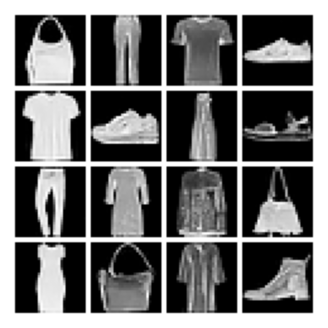

In [34]:
s = torch.load(os.path.join(cfg.out_dir, "samples", "ddpm.pt"))
plt.figure(figsize=(4, 4))
plt.imshow(_grid_np(s[:16], 4), cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()

## Simpan hasil ke zip
Zip berisi semua isi `final_results/` **kecuali checkpoint** (`*.pt` di `checkpoints/`), jadi ukurannya kecil. Download dari panel *Output* Kaggle.

In [32]:
zip_base = os.path.join(BASE, "kaggle_03_ddpm_results")
tmp = zip_base + "_tmp"
shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(cfg.out_dir, tmp, ignore=shutil.ignore_patterns("checkpoints"))
zip_path = shutil.make_archive(zip_base, "zip", tmp)
shutil.rmtree(tmp)
print("Tersimpan:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")

Tersimpan: /kaggle/working/kaggle_03_ddpm_results.zip (0.2 MB)


[14:27:50] Generate 7000 sampel DDPM dalam 14 bagian (0 bagian sudah ada)
[14:32:20] Bagian 1/14 selesai (500 sampel, 270 s) | sisa ±58 menit
[14:36:49] Bagian 2/14 selesai (500 sampel, 268 s) | sisa ±54 menit
[14:41:18] Bagian 3/14 selesai (500 sampel, 269 s) | sisa ±49 menit
[14:45:48] Bagian 4/14 selesai (500 sampel, 269 s) | sisa ±45 menit
[14:50:17] Bagian 5/14 selesai (500 sampel, 269 s) | sisa ±40 menit
[14:54:45] Bagian 6/14 selesai (500 sampel, 267 s) | sisa ±36 menit
[14:59:15] Bagian 7/14 selesai (500 sampel, 270 s) | sisa ±31 menit
[15:03:44] Bagian 8/14 selesai (500 sampel, 269 s) | sisa ±27 menit
[15:08:14] Bagian 9/14 selesai (500 sampel, 269 s) | sisa ±22 menit
[15:12:43] Bagian 10/14 selesai (500 sampel, 269 s) | sisa ±18 menit
[15:17:13] Bagian 11/14 selesai (500 sampel, 269 s) | sisa ±13 menit
[15:21:42] Bagian 12/14 selesai (500 sampel, 269 s) | sisa ±9 menit
[15:26:12] Bagian 13/14 selesai (500 sampel, 269 s) | sisa ±4 menit
[15:30:40] Bagian 14/14 selesai (500 sam

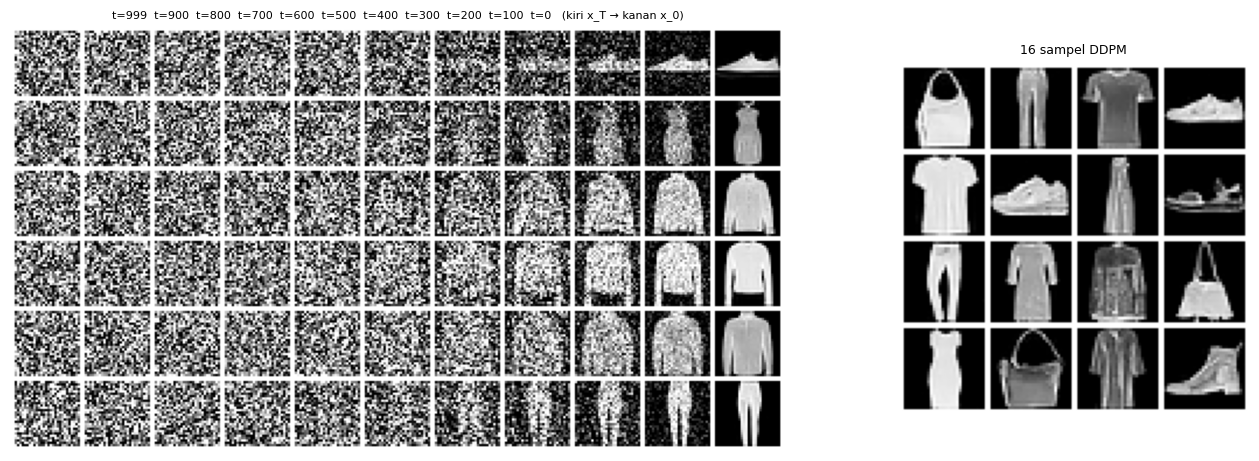

Tersimpan: /kaggle/working/kaggle_03_ddpm_results.zip (15.7 MB)


In [33]:
# ===================== EVALUASI DDPM (RESUMABLE) =====================
# Aman dijalankan berulang kali. Sampel dibuat per bagian (500 sampel) dan tiap bagian
# langsung disimpan ke disk. Kalau cell berhenti, jalankan ulang cell ini: bagian yang
# sudah selesai dilewati, jadi paling banyak hanya mengulang satu bagian (±4-5 menit).
import glob, json, math, os, shutil, time
import numpy as np
import torch
import matplotlib.pyplot as plt

# 0) Pastikan model ada di memori. Kalau kernel sempat restart, model dimuat dari
#    checkpoint di /kaggle/working (training TIDAK diulang).
if not all(v in globals() for v in ("ddpm", "ddpm_hist", "clf")):
    assert os.path.exists(ckpt_path("ddpm")), (
        "Checkpoint DDPM tidak ditemukan di " + ckpt_path("ddpm") + ". Sesi kemungkinan sudah mati.")
    clf = load_or_train("mlp_classifier", lambda: train_classifier(cfg, loaders, device))[0]["model"]
    ddpm, ddpm_hist = load_or_train("ddpm", lambda: train_ddpm_resumable(cfg, loaders, device))
ddpm["ema"].eval()
hist_path = os.path.join(cfg.out_dir, "logs", "ddpm_history.json")
if not os.path.exists(hist_path):
    save_json(ddpm_hist, hist_path)

# 1) Generate sampel untuk FID & coverage, per bagian
N_FID = cfg.fid_n_samples or len(ds["test"])          # 7000, sama dengan model lain
B = cfg.ddpm_sample_batch                              # 500 sampel per bagian
n_parts = math.ceil(N_FID / B)
part_dir = os.path.join(cfg.out_dir, "samples", "ddpm_parts")
os.makedirs(part_dir, exist_ok=True)
log(f"Generate {N_FID} sampel DDPM dalam {n_parts} bagian "
    f"({len(glob.glob(os.path.join(part_dir, 'part_*.pt')))} bagian sudah ada)")
for k in range(n_parts):
    p = os.path.join(part_dir, f"part_{k:03d}.pt")
    if os.path.exists(p):
        continue
    b = min(B, N_FID - k * B)
    g = torch.Generator(device=device).manual_seed(cfg.seed + 1 + k)   # seed per bagian -> bisa dilanjutkan
    t0 = time.perf_counter()
    x0, _ = ddpm["diffusion"].sample(ddpm["ema"], b, device, generator=g, amp=cfg.ddpm_amp)
    dt = time.perf_counter() - t0
    torch.save({"x": to_01(x0).cpu(), "seconds": dt}, p + ".tmp")
    os.replace(p + ".tmp", p)                          # tulis atomik: file setengah jadi tidak terbaca
    sisa = n_parts - len(glob.glob(os.path.join(part_dir, "part_*.pt")))
    log(f"Bagian {k + 1}/{n_parts} selesai ({b} sampel, {dt:.0f} s) | sisa ±{sisa * dt / 60:.0f} menit")
parts = [torch.load(os.path.join(part_dir, f"part_{k:03d}.pt"), weights_only=False) for k in range(n_parts)]
samples = torch.cat([q["x"] for q in parts])
gen_time = sum(q["seconds"] for q in parts)
torch.save(samples[:256], os.path.join(cfg.out_dir, "samples", "ddpm.pt"))
log(f"Semua sampel siap: {tuple(samples.shape)}, total waktu generate {gen_time / 60:.1f} menit")

# 2) Latency sampling 1000 langkah untuk batch 64 (disimpan, jadi tidak diukur ulang)
lat_path = os.path.join(cfg.out_dir, "metrics", "ddpm_latency.json")
if os.path.exists(lat_path):
    lat = json.load(open(lat_path))
else:
    log("Mengukur latency (1 warmup + %d run, ±30 detik per run) ..." % cfg.latency_runs_ddpm)
    g_lat = torch.Generator(device=device).manual_seed(cfg.seed + 1)
    lat = measure_latency(lambda: ddpm["diffusion"].sample(ddpm["ema"], cfg.latency_batch, device,
                                                           generator=g_lat, amp=cfg.ddpm_amp),
                          device, n_warmup=1, n_runs=cfg.latency_runs_ddpm)
    save_json(lat, lat_path)

# 3) FID, coverage, simpan metrik
fid_eval = make_fid()
r = {"model": PRETTY["ddpm"],
     "train_time_per_epoch_s": float(np.mean(ddpm_hist["epoch_time"])),
     "params": count_params(ddpm["unet"]),
     "latent_dim": "1x28x28 (dimensi citra)",
     "latency_generate": lat,
     "generate_time_total_s": gen_time,
     "fid_n_samples": N_FID,
     "coverage": class_coverage(clf, samples, device)}
if fid_eval is not None:
    r["fid"] = fid_eval.score(samples)
r["loss_cv_tail"] = loss_stability(ddpm_hist["train_loss"])
save_json(r, os.path.join(cfg.out_dir, "metrics", "ddpm.json"))
print(f"FID: {r.get('fid', 'N/A')} | latency/batch64: {lat['median_ms'] / 1000:.1f} s"
      f" | generate {N_FID} sampel: {gen_time / 60:.1f} menit")
print("Distribusi kelas:", [round(p, 3) for p in r["coverage"]["class_hist"]])

# 4) Trajektori reverse diffusion (bagian bawah Figur 5)
traj_path = os.path.join(cfg.out_dir, "samples", "ddpm_trajectory.pt")
if os.path.exists(traj_path):
    traj = torch.load(traj_path, weights_only=False)
else:
    g_traj = torch.Generator(device=device).manual_seed(cfg.seed + 7)
    _, traj = ddpm["diffusion"].sample(ddpm["ema"], 6, device, generator=g_traj,
                                       traj_every=max(1, cfg.ddpm_T // 10), amp=cfg.ddpm_amp)
    torch.save(traj, traj_path)
imgs = torch.cat([to_01(x) for _, x in traj], 0).view(len(traj), 6, 1, 28, 28).transpose(0, 1).reshape(-1, 1, 28, 28)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].imshow(_grid_np(imgs, len(traj)), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("  ".join(f"t={t}" for t, _ in traj) + "   (kiri x_T → kanan x_0)", fontsize=8)
axes[1].imshow(_grid_np(samples[:16], 4), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("16 sampel DDPM", fontsize=9)
for a in axes:
    a.axis("off")
plt.show()

# 5) Zip hasil (tanpa checkpoint dan tanpa potongan sampel)
zip_base = os.path.join(BASE, "kaggle_03_ddpm_results")
tmp = zip_base + "_tmp"
shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(cfg.out_dir, tmp, ignore=shutil.ignore_patterns("checkpoints", "ddpm_parts"))
zip_path = shutil.make_archive(zip_base, "zip", tmp)
shutil.rmtree(tmp)
print("Tersimpan:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")